In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from dataset.dataset import load_data
from dataset.utils import *
import matplotlib.pyplot as plt

from models.cem import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from captum.attr import IntegratedGradients, LRP

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
device = "cpu"
if torch.cuda.is_available():
    print("Device:", device, torch.cuda.get_device_name(0))
else:
    print("Device:", device)

Device: cpu NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [3]:
##### https://github.com/fhvilshoj/TorchLRP/blob/74253a1be05f0be0b7c535736023408670443b6e/examples/visualization.py#L60
def heatmap(X, cmap_name="seismic"):
	cmap = plt.cm.get_cmap(cmap_name)

	if X.shape[1] in [1, 3]:  # move channel index to end + convert to np array
		X = X.permute(0, 2, 3, 1).detach().cpu().numpy()
	if isinstance(X, torch.Tensor):  # convert tensor to np array
		X = X.detach().cpu().numpy()

	shape = X.shape
	tmp = X.sum(axis=-1) # Reduce channel axis

	tmp = project(tmp, output_range=(0, 255)).astype(int)
	tmp = cmap(tmp.flatten())[:, :3].T
	tmp = tmp.T

	shape = list(shape)
	shape[-1] = 3
	return tmp.reshape(shape).astype(np.float32)


def project(X, output_range=(0, 1)):
	absmax = np.abs(X).max(axis=tuple(range(1, len(X.shape))), keepdims=True)
	X /= absmax + (absmax == 0).astype(float)
	X = (X+1) / 2. # range [0, 1]
	X = output_range[0] + X * (output_range[1] - output_range[0]) # range [x, y]
	return X

In [4]:
# single playing card dataset has 17 concepts
# multi card dataset has 52 concepts


"""
N_CONCEPT = 17
N_CLASSES = 52
val_loader = load_data("./dataset/playing-cards/splits/single/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/playing-cards/", return_orig=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/playing-cards/splits/single/concepts.txt")
"""

"""
N_CONCEPT = 52
N_CLASSES = 6
val_loader = load_data("./dataset/playing-cards/splits/three_card_poker/val.pkl", 16, dataset_root="./dataset/playing-cards", return_orig=True, num_concepts=N_CONCEPT, resampling=True)

concept_index_to_string = IndexToString("./dataset/playing-cards/splits/three_card_poker/concepts.txt")
"""

N_CONCEPT = 112
N_CLASSES = 200
val_loader = load_data("./dataset/CUB_200_2011/splits/CBM/val.pkl", 16, dataset_root="./dataset/CUB_200_2011", return_orig=True, num_concepts=N_CONCEPT, resampling=True)

concept_index_to_string = IndexToString("./dataset/CUB_200_2011/splits/CBM/concepts.txt")


XtoCtoY = End2EndModel(num_classes=N_CLASSES, num_concepts=N_CONCEPT, emb_size=16, shared_prob_gen=False, sigmoidal_embedding=False, sigmoidal_prob=True)
XtoCtoY.load_state_dict(torch.load("./saves/cem_cub_new.pth", map_location=torch.device('cpu')), strict=False)
XtoCtoY.to(device)
XtoCtoY.eval()

print("model loaded")

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and will be removed in 0.15, please use 'weights' instead.
  warnings.warn(
/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and will be removed in 0.15. The current behavior is equivalent to passing `weights=VGG16_BN_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_BN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


model loaded


In [5]:
print(XtoCtoY.x_to_c_model)

XtoCNet(
  (pre_concept_model): VGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (9): ReLU(inplace=True)
      (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (12): ReLU(inplace=True)
      (13): MaxPool2d(kernel_size=2, stride=2, pad

In [6]:
#lrp = LRP(XtoCtoY.x_to_c_model)
ig = IntegratedGradients(XtoCtoY.x_to_c_model)

## Show true concepts and classification + predicted concepts and classification

True image size (channels, width, height): torch.Size([3, 299, 299])
True  image concepts: tensor([0., 0., 0., 1., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 1., 0., 0.,
        0., 0., 1., 1., 1., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0.,
        1., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 1., 0., 1., 0.,
        1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 0., 0., 1., 0., 0., 0.,
        0., 0., 1., 1., 1., 0., 1., 0., 0., 0., 1., 0., 1., 0., 0., 0., 0., 1.,
        1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0.,
        0., 0., 1., 0.])


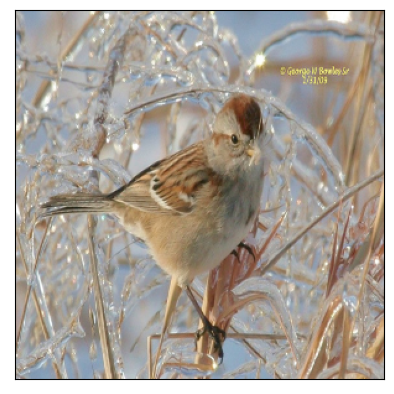

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


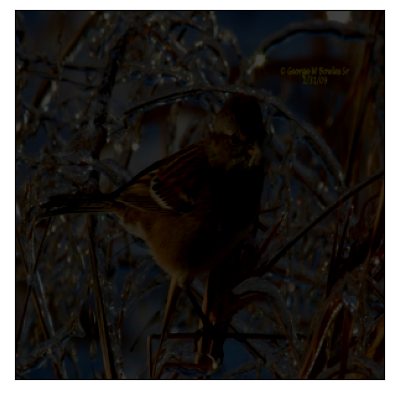

In [13]:
imageId = 7

images, labels, concepts, original_imgs = next(iter(val_loader))
image, label = images[imageId].to(device), labels[imageId].to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts[imageId])

plt.xticks([])
plt.yticks([])
plt.imshow(original_imgs[imageId].squeeze().permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(images[imageId].squeeze().permute(1, 2, 0))
plt.show()

In [14]:
image, label = images[imageId].to(device), labels[imageId].to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoCtoY(image)

pred_concepts = torch.nn.Sigmoid()(torch.cat(prediction[0], dim=1))

print("Predicted concepts:", pred_concepts)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

Predicted concepts: tensor([[    0.0000,     0.0000,     0.0042,     0.9992,     1.0000,     0.0004,
             0.0000,     0.1073,     0.0004,     0.9956,     0.9920,     0.0166,
             0.0000,     0.0151,     0.0001,     0.9854,     0.0000,     0.0005,
             0.0000,     0.0001,     0.9672,     0.7680,     0.8391,     0.0004,
             0.0000,     0.9990,     0.0097,     0.0000,     0.0485,     0.0000,
             0.9527,     0.9678,     0.5168,     0.0078,     0.0020,     0.0043,
             0.9910,     0.0002,     0.0000,     0.0000,     0.0051,     0.0000,
             0.0001,     0.8513,     0.1969,     0.0003,     0.0000,     0.0032,
             0.8155,     0.0951,     0.9817,     0.0005,     0.9993,     0.0000,
             0.8040,     0.0075,     0.0001,     0.1119,     0.0000,     0.8361,
             0.0009,     0.0020,     0.0000,     0.9962,     0.0768,     0.1187,
             0.0000,     0.0007,     0.0277,     0.5763,     0.0000,     0.0172,
        

## Generate saliency maps for concept probabilities

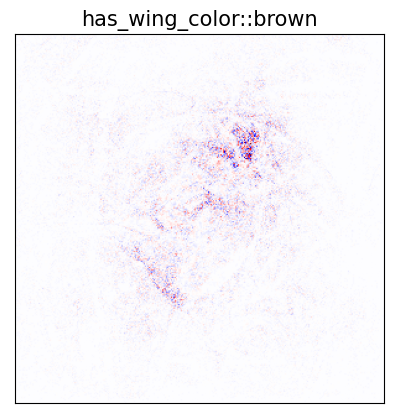

In [16]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

target = 4
#attribution = lrp.attribute(image, target=target)
attribution = ig.attribute(image, target=target, additional_forward_args=(False,"probs"))


attr = heatmap(attribution, cmap_name='seismic')

plt.xticks([])
plt.yticks([])
plt.title(label=concept_index_to_string(target), fontsize=15)
plt.imshow(attr.squeeze(), cmap='seismic')
#plt.savefig(f'temp/{target}.png')
plt.show()

plt.close() 

## Generate saliency maps for concept vector neurons

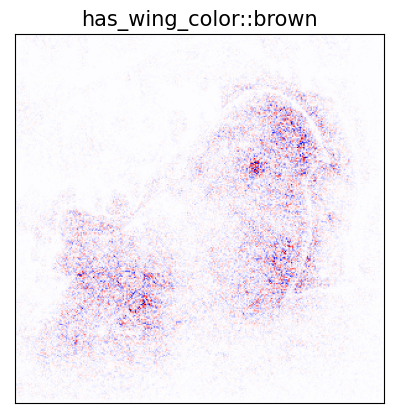

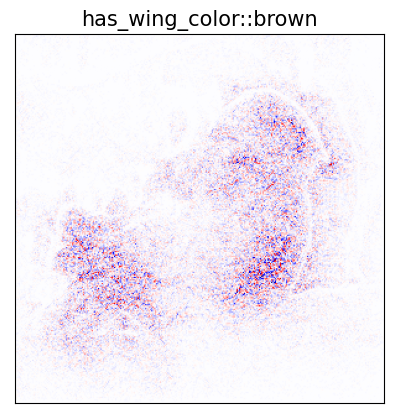

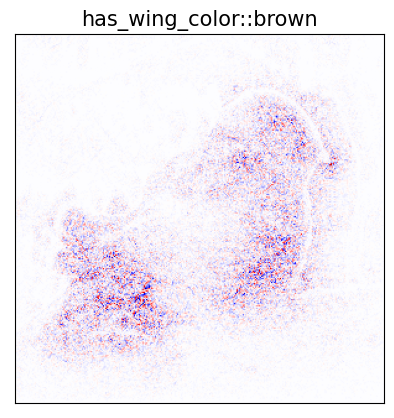

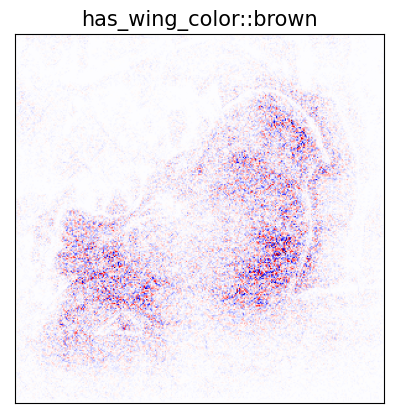

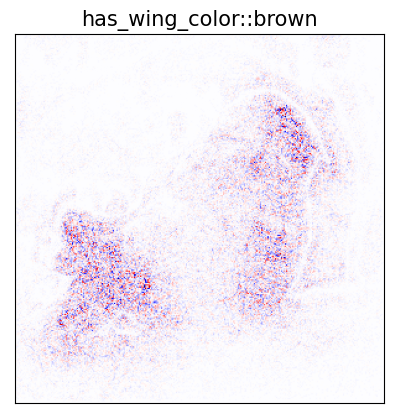

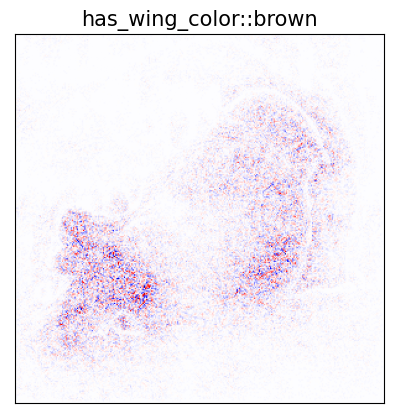

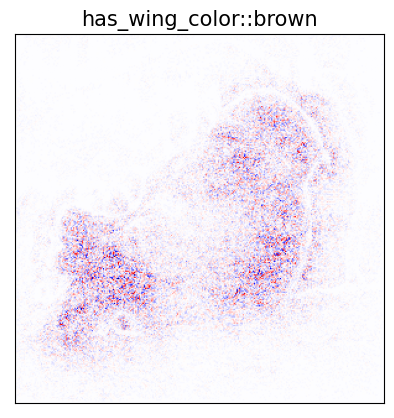

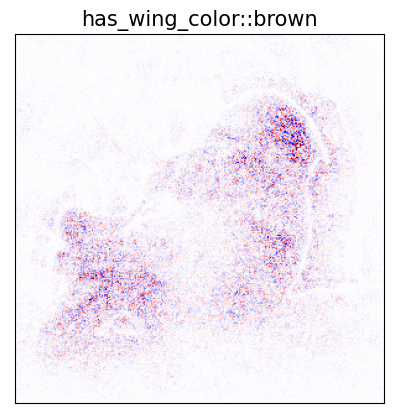

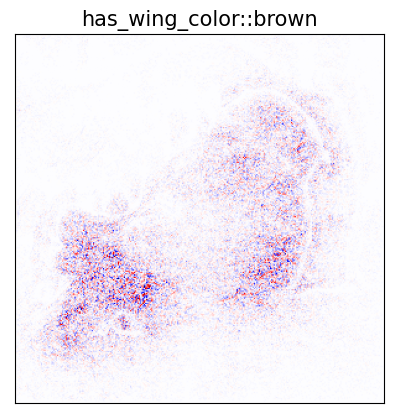

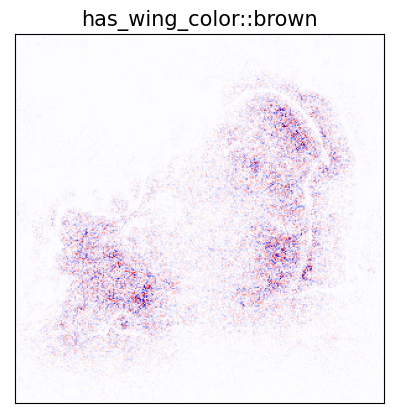

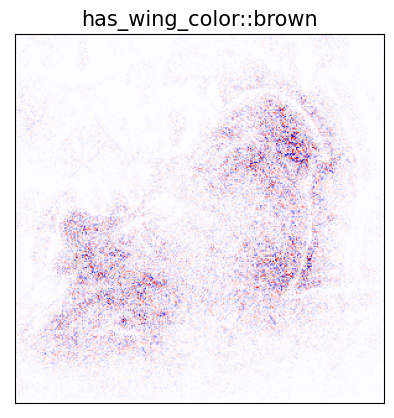

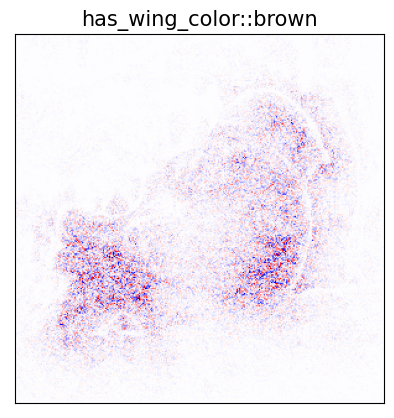

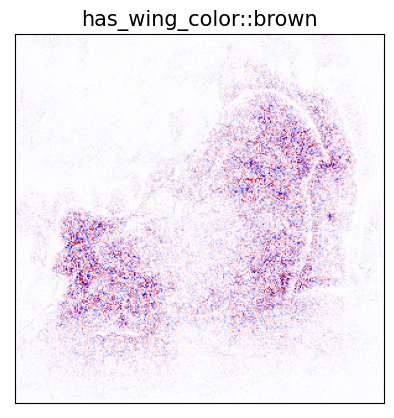

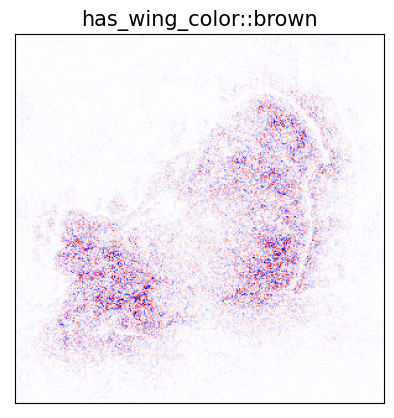

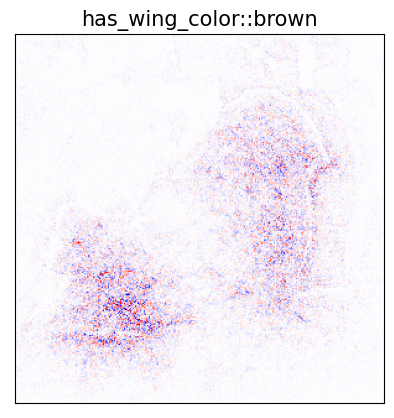

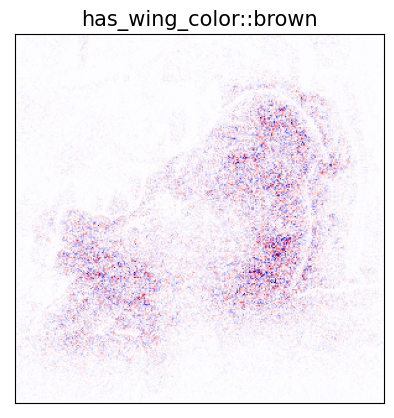

combined


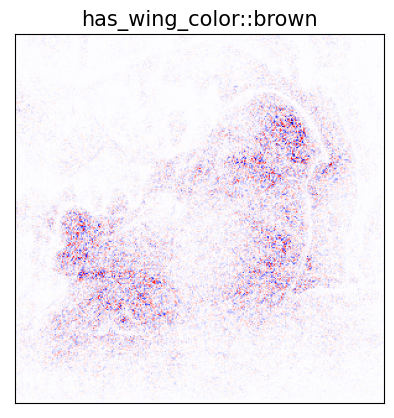

In [11]:
image, label = images[imageId].to(device), labels[imageId].to(device)
#image, label = images.to(device), labels.to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

target = 4

all_neurons = []

for i in range((target*16), (target*16) + 16):
	#attribution = lrp.attribute(image, target=target)
	attribution = ig.attribute(image, target=i, additional_forward_args=(False,"concepts"))

	all_neurons.append(attribution)

	attr = heatmap(attribution, cmap_name='seismic')

	plt.xticks([])
	plt.yticks([])
	plt.title(label=concept_index_to_string(target), fontsize=15)
	plt.imshow(attr.squeeze(), cmap='seismic')
	#plt.savefig(f'temp/{target}.png')
	plt.show()

	plt.close() 
	
	
all_neurons = torch.Tensor(torch.cat(all_neurons, dim=0))

attr = heatmap(torch.mean(all_neurons, dim=0).unsqueeze(0), cmap_name='seismic')

print("combined")

plt.xticks([])
plt.yticks([])
plt.title(label=concept_index_to_string(target), fontsize=15)
plt.imshow(attr.squeeze(), cmap='seismic')
#plt.savefig(f'temp/{target}.png')
plt.show()

plt.close()